In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)


In [6]:
FILE_PATH = "../datasets/household_power_consumption.csv"  # change if needed

df = pd.read_csv(
    FILE_PATH,
    sep=",",                 # change to ";" if required
    na_values=["?", "NA", ""],
    low_memory=False
)

print("Dataset loaded successfully")
print("Shape:", df.shape)


Dataset loaded successfully
Shape: (1048575, 9)


In [7]:
df.head()


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [8]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   1048575 non-null  str    
 1   Time                   1048575 non-null  str    
 2   Global_active_power    1044506 non-null  float64
 3   Global_reactive_power  1044506 non-null  float64
 4   Voltage                1044506 non-null  float64
 5   Global_intensity       1044506 non-null  float64
 6   Sub_metering_1         1044506 non-null  float64
 7   Sub_metering_2         1044506 non-null  float64
 8   Sub_metering_3         1044506 non-null  float64
dtypes: float64(7), str(2)
memory usage: 72.0 MB


In [9]:
df.columns


Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

In [10]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.sort_values("Datetime").reset_index(drop=True)

print("Datetime conversion done")


Datetime conversion done


In [11]:
missing_counts = df.isna().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": missing_percent
})

missing_df.sort_values("Missing_Percentage", ascending=False)


,Missing_Count,Missing_Percentage
Global_active_power,4069,0.38805
Global_reactive_power,4069,0.38805
Voltage,4069,0.38805
Global_intensity,4069,0.38805
Sub_metering_1,4069,0.38805
Sub_metering_2,4069,0.38805
Sub_metering_3,4069,0.38805
Datetime,0,0.00000


In [12]:
time_diffs = df["Datetime"].diff().value_counts().head(10)
time_diffs


Datetime
0 days 00:01:00    1048574
Name: count, dtype: int64

In [13]:
df.describe()


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
count,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06,1048575
mean,1.108202e+00,1.182732e-01,2.399598e+02,4.718123e+00,1.177451e+00,1.475177e+00,5.933837e+00,2007-12-15 19:31:00
min,7.600000e-02,0.000000e+00,2.234900e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,2006-12-16 17:24:00
25%,2.880000e-01,0.000000e+00,2.379700e+02,1.200000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2007-06-16 18:27:30
50%,5.500000e-01,9.800000e-02,2.402100e+02,2.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2007-12-15 19:31:00
75%,1.544000e+00,1.860000e-01,2.421400e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01,2008-06-14 20:34:30
max,1.067000e+01,1.390000e+00,2.521400e+02,4.640000e+01,8.000000e+01,7.800000e+01,3.100000e+01,2008-12-13 21:38:00
std,1.129546e+00,1.095062e-01,3.284504e+00,4.763588e+00,6.321183e+00,6.352703e+00,8.210398e+00,NaN


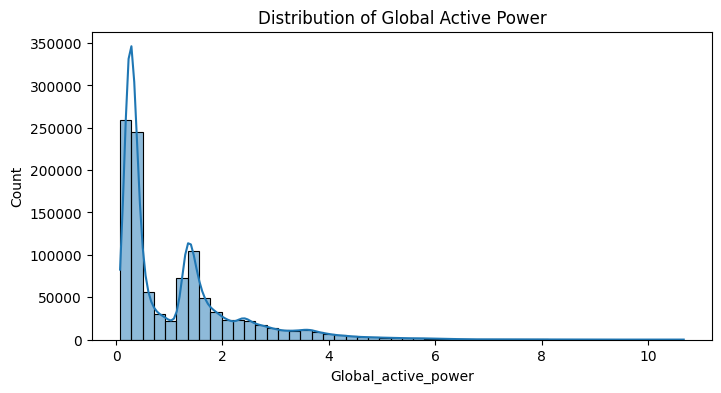

In [14]:
plt.figure(figsize=(8,4))
sns.histplot(df["Global_active_power"].dropna(), bins=50, kde=True)
plt.title("Distribution of Global Active Power")
plt.show()


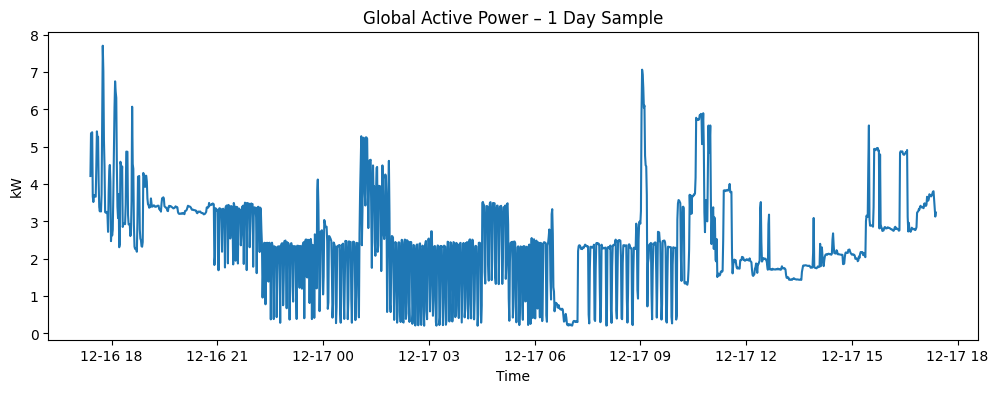

In [15]:
sample_df = df.set_index("Datetime").iloc[:1440]  # first 1 day

plt.figure(figsize=(12,4))
plt.plot(sample_df["Global_active_power"])
plt.title("Global Active Power – 1 Day Sample")
plt.xlabel("Time")
plt.ylabel("kW")
plt.show()


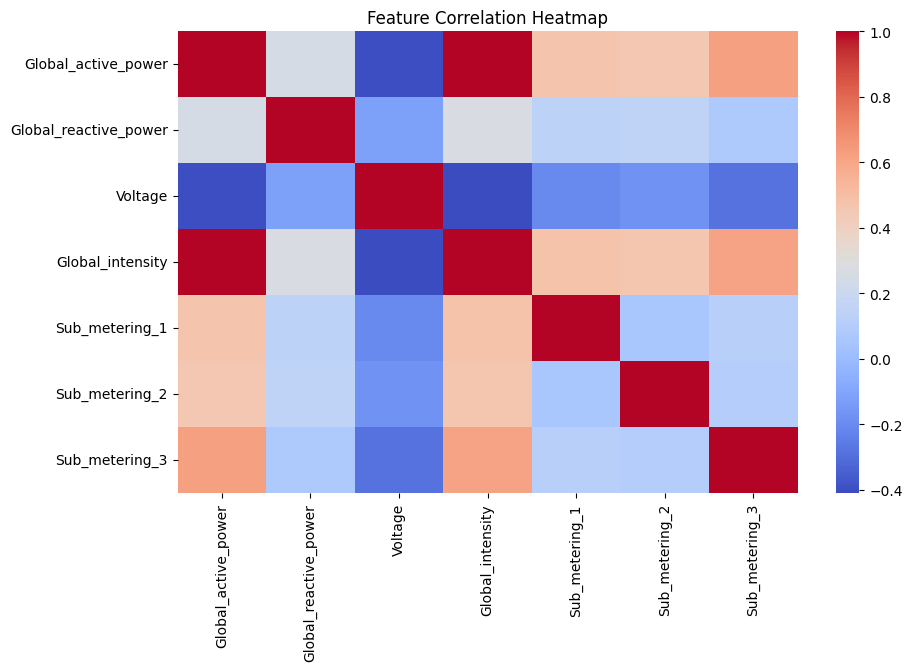

In [16]:
plt.figure(figsize=(10,6))
sns.heatmap(
    df.drop(columns=["Datetime"]).corr(),
    cmap="coolwarm",
    annot=False
)
plt.title("Feature Correlation Heatmap")
plt.show()
